## EDA task 1

This notebook continues the original Task 1 work and expands it into a reproducible EDA.

## 1. Dataset Loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
SEED = 342
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

# This notebook is stored in notebook/, so the data path remains portable.
DATA_ROOT = Path('../../cpe342-kaggle-main')

def quality_report(frame, id_col='player_id'):
    numeric = frame.select_dtypes(include=np.number)
    missing = pd.DataFrame({
        'missing_count': frame.isna().sum(),
        'missing_pct': frame.isna().mean().mul(100)
    }).sort_values('missing_count', ascending=False)
    print(f'Duplicate rows: {frame.duplicated().sum():,}')
    print(f'Duplicate {id_col}s: {frame[id_col].duplicated().sum():,}')
    print(f'Infinite numeric values: {np.isinf(numeric).sum().sum():,}')
    display(missing.query('missing_count > 0'))
    constants = frame.columns[frame.nunique(dropna=False).le(1)].tolist()
    near_constant = (frame.nunique(dropna=False) / len(frame)).sort_values().head(10)
    print('Constant features:', constants or 'None')
    display(near_constant.to_frame('unique_ratio'))
    return missing

def plot_missing(missing, title):
    shown = missing.query('missing_count > 0').head(25)
    if shown.empty:
        print('No missing values to plot.')
        return
    fig, ax = plt.subplots(figsize=(10, max(3, len(shown) * .3)))
    sns.barplot(data=shown.reset_index(), y='index', x='missing_pct', ax=ax, color='#4C72B0')
    ax.set(title=title, xlabel='Missing values (%)', ylabel='Column')
    plt.show(); plt.close()

def strong_correlations(frame, threshold=.75):
    corr = frame.select_dtypes(include=np.number).corr()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().rename('correlation').reset_index()
    return pairs.loc[pairs.correlation.abs().ge(threshold)].sort_values('correlation', key=np.abs, ascending=False)


In [2]:
train = pd.read_csv(DATA_ROOT / '01_binary_classification/train.csv')
print('Train shape:', train.shape)
print(f'Memory usage: {train.memory_usage(deep=True).sum()/1024**2:.2f} MiB')
display(train.head())
display(train.dtypes.rename('dtype').to_frame())
display(train.describe(include='all').T)
display(train.nunique(dropna=False).rename('unique_values').to_frame().sort_values('unique_values'))

test = pd.read_csv(DATA_ROOT / '01_binary_classification/test.csv')
print('Test shape:', test.shape)
print('Columns differing from train:', sorted(set(train.columns).symmetric_difference(test.columns)))
display(pd.DataFrame({'train_missing_pct': train.isna().mean().mul(100), 'test_missing_pct': test.isna().mean().mul(100)}).query('train_missing_pct > 0 or test_missing_pct > 0'))


Train shape: (104000, 33)
Memory usage: 26.88 MiB


,player_id,kill_death_ratio,headshot_percentage,win_rate,accuracy_score,kill_consistency,reaction_time_ms,account_age_days,level,level_progression_speed,friend_network_size,reports_received,device_changes_count,input_consistency_score,avg_session_length_min,sessions_per_day,night_play_ratio,weapon_switch_speed,movement_pattern_score,aiming_smoothness,spray_control_score,game_sense_score,communication_rate,team_play_score,buy_decision_score,map_knowledge,clutch_success_rate,first_blood_rate,survival_time_avg,damage_per_round,utility_usage_rate,crosshair_placement,is_cheater
0,P001337,5.176237,54.245482,85.662938,25.457845,0.774864,83.828120,261.721035,34.009104,0.022950,236.0,18.0,6.0,0.677432,95.887281,0.474047,0.227285,0.852975,0.571246,0.753536,NaN,0.973228,0.467505,0.692063,0.834387,0.550694,0.491093,0.483104,73.476007,55.711383,0.790575,0.893005,0.0
1,P044854,6.510362,54.388554,99.174621,36.679574,0.813276,148.295650,1075.704820,72.863639,0.067318,245.0,6.0,NaN,0.750639,NaN,4.014277,0.652659,NaN,0.812029,0.852174,0.802251,0.706048,0.733649,0.616427,0.853019,0.556390,0.562038,NaN,NaN,NaN,0.793743,0.956779,0.0
2,P036798,5.457167,60.417905,100.000000,44.558707,0.720939,117.662956,1031.540114,99.075389,0.055238,200.0,11.0,NaN,0.680099,237.564202,5.944288,0.243013,0.806776,0.551104,0.976854,0.694628,0.774723,NaN,NaN,0.362643,0.579663,0.129658,0.335847,40.784374,NaN,0.563563,0.868322,0.0
3,P079617,NaN,35.180729,67.756853,42.750853,0.379890,348.463623,525.534446,39.694695,0.028952,63.0,NaN,2.0,0.600773,81.064775,8.009966,0.437024,0.600335,0.532279,0.832989,0.648569,0.898685,0.261991,0.501457,0.398195,0.630693,0.512969,0.178991,60.185066,135.341158,NaN,0.938778,NaN
4,P093830,3.747774,31.777986,80.689833,26.820793,0.567326,351.819822,296.179584,72.817519,0.040610,74.0,11.0,2.0,0.515087,194.142157,5.366525,NaN,NaN,0.701030,0.641468,0.633545,0.715866,0.457803,0.548742,0.485381,0.578093,0.421014,0.154923,59.359891,127.075580,0.471941,0.837420,NaN


,dtype
player_id,str
kill_death_ratio,float64
headshot_percentage,float64
win_rate,float64
accuracy_score,float64
kill_consistency,float64
reaction_time_ms,float64
account_age_days,float64
level,float64
level_progression_speed,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
player_id,104000,104000,P001337,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kill_death_ratio,93962.0,NaN,NaN,NaN,4.737964,1.517484,0.5,3.711771,4.566687,5.536477,12.0
headshot_percentage,101187.0,NaN,NaN,NaN,47.861135,13.753128,5.0,38.270544,47.128207,56.653761,95.0
win_rate,98817.0,NaN,NaN,NaN,71.36147,13.995451,16.384967,61.672293,71.137088,80.996094,100.0
accuracy_score,103356.0,NaN,NaN,NaN,40.187533,12.119357,8.0,31.707278,39.674507,48.11147,85.0
kill_consistency,94269.0,NaN,NaN,NaN,0.64868,0.150382,0.25,0.543608,0.652679,0.756085,0.98
reaction_time_ms,95881.0,NaN,NaN,NaN,135.173335,51.095458,55.0,99.553841,128.430912,162.476155,714.445534
account_age_days,88983.0,NaN,NaN,NaN,495.25396,350.934765,1.005388,156.222168,479.877057,762.091007,1499.649904
level,96586.0,NaN,NaN,NaN,62.865924,20.743244,25.005696,44.905046,62.862321,80.77261,99.998795
level_progression_speed,95560.0,NaN,NaN,NaN,0.364644,1.595146,0.002926,0.040625,0.08128,0.213961,80.028706


,unique_values
is_cheater,3
device_changes_count,17
reports_received,27
friend_network_size,351
aiming_smoothness,75615
survival_time_avg,78696
weapon_switch_speed,78788
avg_session_length_min,80106
movement_pattern_score,80677
communication_rate,82599


Test shape: (25889, 32)
Columns differing from train: ['is_cheater']


,train_missing_pct,test_missing_pct
account_age_days,14.439423,0.556221
accuracy_score,0.619231,2.275098
aiming_smoothness,20.875000,2.062652
avg_session_length_min,22.975962,1.575959
buy_decision_score,12.638462,11.120553
clutch_success_rate,2.451923,13.534706
communication_rate,20.578846,11.043300
crosshair_placement,12.801923,2.784967
damage_per_round,9.095192,12.827842
device_changes_count,2.959615,13.577195


## 2. Dataset Overview

`player_id` is an identifier and should be excluded from future feature matrices unless a justified, leakage-safe use is established.

## 3. Data Quality Assessment

Duplicate rows: 0
Duplicate player_ids: 0
Infinite numeric values: 0


,missing_count,missing_pct
survival_time_avg,25305,24.331731
weapon_switch_speed,25213,24.243269
avg_session_length_min,23895,22.975962
movement_pattern_score,23324,22.426923
friend_network_size,23265,22.370192
reports_received,23193,22.300962
aiming_smoothness,21710,20.875000
communication_rate,21402,20.578846
team_play_score,20235,19.456731
spray_control_score,17428,16.757692


Constant features: None


,unique_ratio
is_cheater,0.000029
device_changes_count,0.000163
reports_received,0.000260
friend_network_size,0.003375
aiming_smoothness,0.727067
survival_time_avg,0.756692
weapon_switch_speed,0.757577
avg_session_length_min,0.770250
movement_pattern_score,0.775740
communication_rate,0.794221


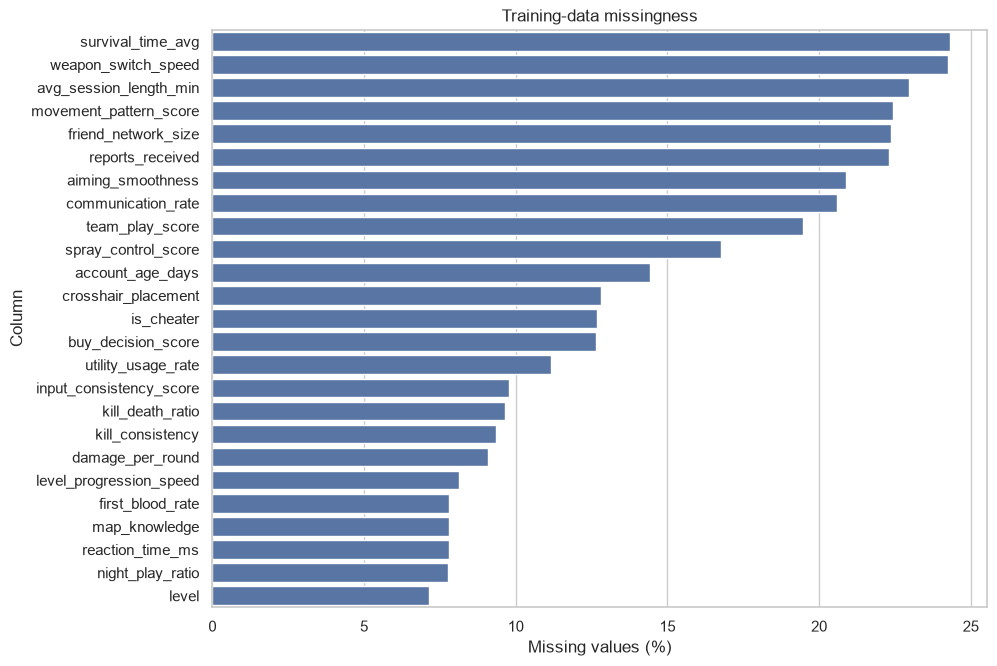

,min,1%,5%,50%,95%,99%,max
kill_death_ratio,0.500000,1.882263,2.616765,4.566687,7.466890,9.500765,12.000000
headshot_percentage,5.000000,18.985354,26.557800,47.128207,71.562414,84.223883,95.000000
win_rate,16.384967,39.574524,48.479658,71.137088,96.072074,100.000000,100.000000
accuracy_score,8.000000,14.344050,21.097806,39.674507,60.969160,70.488432,85.000000
kill_consistency,0.250000,0.300987,0.394750,0.652679,0.893433,0.980000,0.980000
reaction_time_ms,55.000000,55.000000,62.979940,128.430912,227.481762,294.091150,714.445534
account_age_days,1.005388,8.375123,31.339779,479.877057,1117.260695,1361.212002,1499.649904
level,25.005696,27.048239,30.631028,62.862321,95.038277,98.950828,99.998795
level_progression_speed,0.002926,0.009158,0.016450,0.081280,1.272266,4.658701,80.028706
friend_network_size,0.000000,3.000000,15.000000,135.000000,276.000000,330.000000,349.000000


In [3]:
missing = quality_report(train)
plot_missing(missing, 'Training-data missingness')

# Examine numerical extremes without changing the data.
numeric_summary = train.select_dtypes(include=np.number).describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
display(numeric_summary[['min','1%','5%','50%','95%','99%','max']])

## 4. Target Analysis

,count,percent_of_labelled_rows
is_cheater,,
0.0,59091,65.066728
1.0,31725,34.933272


Rows with missing target: 13,184 (12.68%)


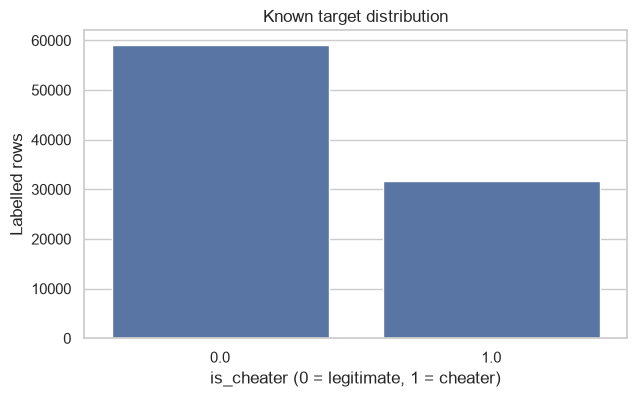

In [4]:
labelled = train.dropna(subset=['is_cheater']).copy()
target_counts = labelled['is_cheater'].value_counts().sort_index()
target_pct = target_counts.div(len(labelled)).mul(100)
display(pd.DataFrame({'count': target_counts, 'percent_of_labelled_rows': target_pct}))
print(f'Rows with missing target: {len(train)-len(labelled):,} ({(1-len(labelled)/len(train))*100:.2f}%)')
fig, ax = plt.subplots(figsize=(7,4))
sns.countplot(data=labelled, x='is_cheater', ax=ax, color='#4C72B0')
ax.set(title='Known target distribution', xlabel='is_cheater (0 = legitimate, 1 = cheater)', ylabel='Labelled rows')
plt.show(); plt.close()


## 5. Feature Distribution Analysis

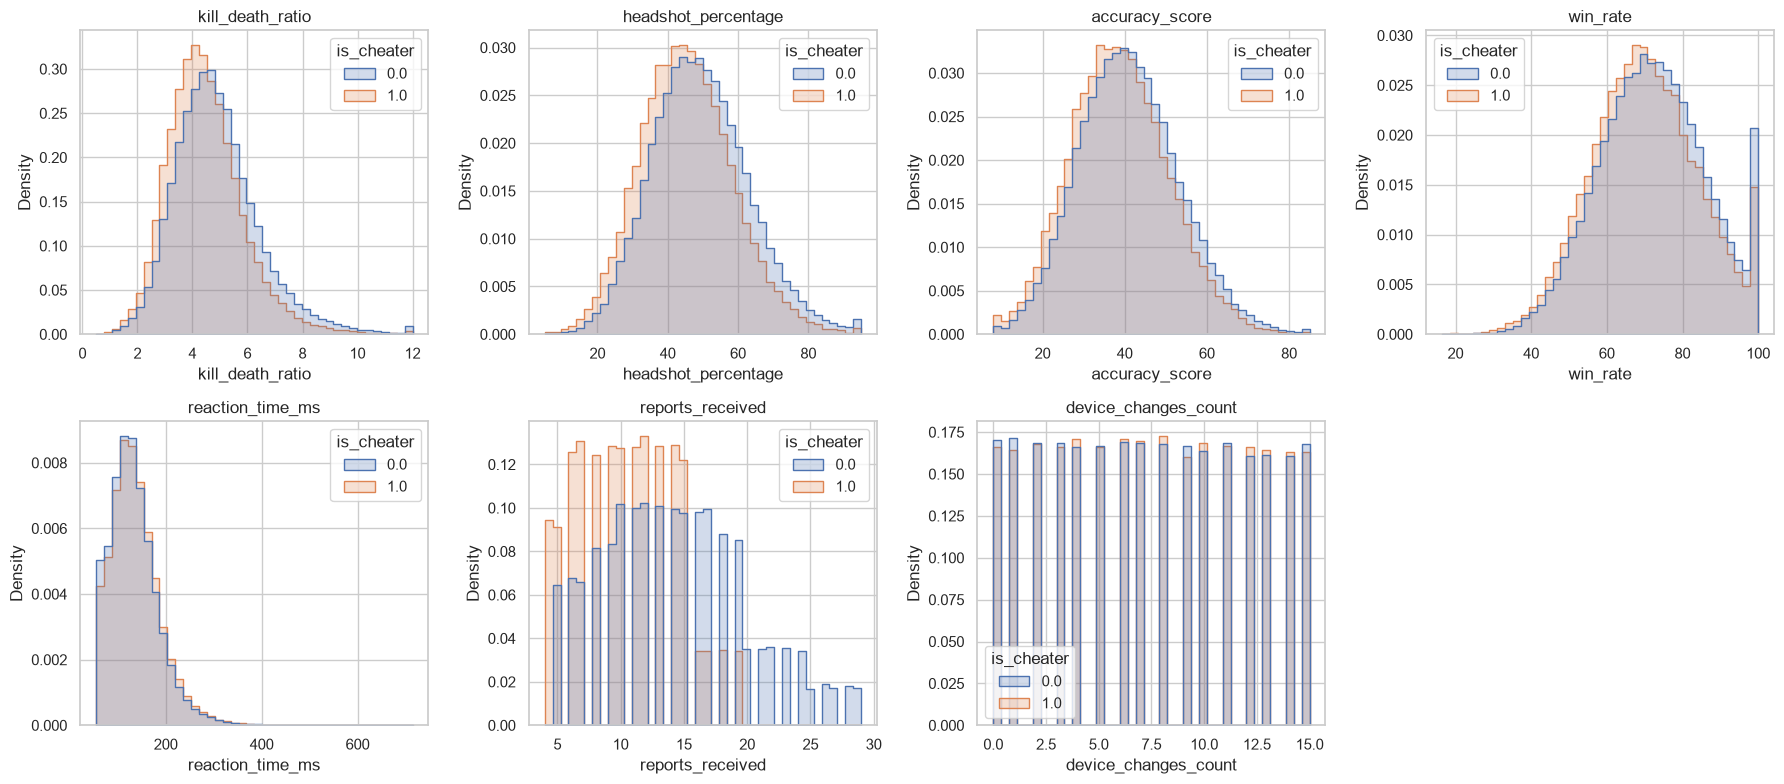

Skewness (largest absolute values):


,skewness
level_progression_speed,18.233971
reaction_time_ms,1.095847
kill_death_ratio,0.941184
reports_received,0.612577
aiming_smoothness,-0.493360
account_age_days,0.396844
headshot_percentage,0.323001
spray_control_score,-0.305659
input_consistency_score,-0.285644
accuracy_score,0.252612


In [5]:
feature_cols = [c for c in train.columns if c not in ['player_id', 'is_cheater']]
selected = ['kill_death_ratio','headshot_percentage','accuracy_score','win_rate','reaction_time_ms','reports_received','device_changes_count']
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, col in zip(axes, selected):
    sns.histplot(data=train, x=col, hue='is_cheater', stat='density', common_norm=False, bins=40, ax=ax, element='step')
    ax.set_title(col)
for ax in axes[len(selected):]: ax.remove()
plt.tight_layout(); plt.show(); plt.close()

print('Skewness (largest absolute values):')
display(train[feature_cols].skew().sort_values(key=np.abs, ascending=False).head(15).rename('skewness').to_frame())

## 6. Feature Relationships

,correlation_with_is_cheater
reports_received,-0.336699
crosshair_placement,-0.227781
kill_death_ratio,-0.134353
headshot_percentage,-0.132846
game_sense_score,-0.125478
account_age_days,-0.098397
accuracy_score,-0.089009
level,-0.082085
spray_control_score,-0.076628
friend_network_size,-0.070805


,level_0,level_1,correlation


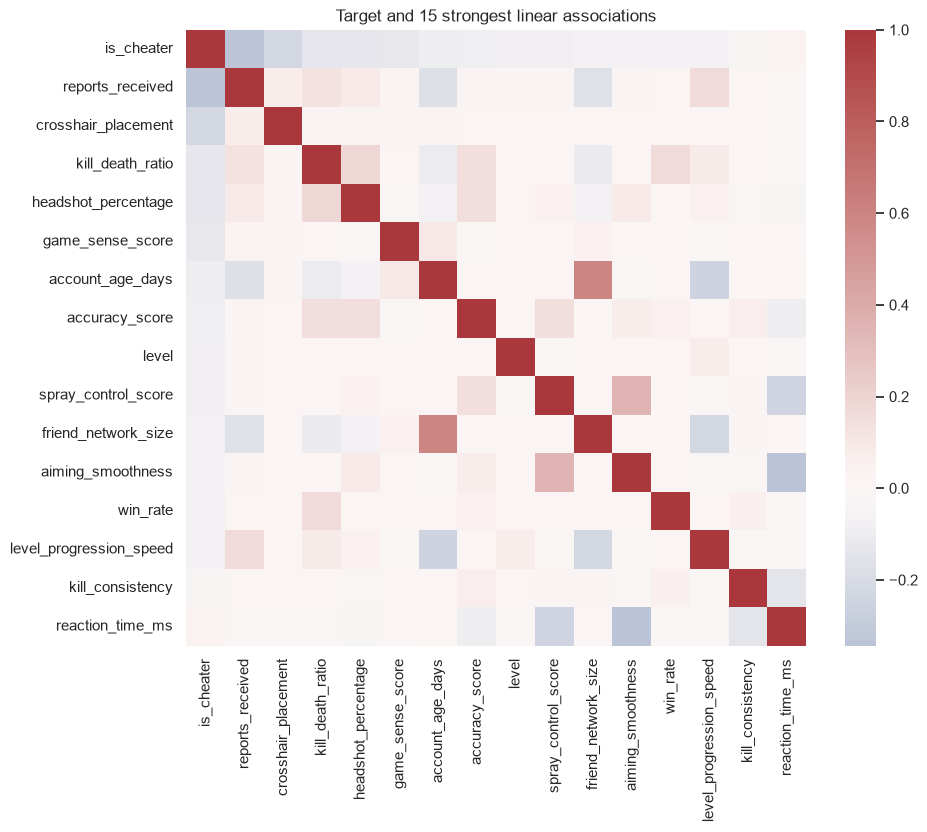

In [6]:
numeric = train.select_dtypes(include=np.number)
corr_to_target = numeric.corrwith(train['is_cheater']).drop('is_cheater').sort_values(key=np.abs, ascending=False)
display(corr_to_target.head(15).rename('correlation_with_is_cheater').to_frame())
display(strong_correlations(train.drop(columns=['player_id','is_cheater'])))
plt.figure(figsize=(10,8))
sns.heatmap(numeric[['is_cheater'] + corr_to_target.head(15).index.tolist()].corr(), cmap='vlag', center=0, annot=False)
plt.title('Target and 15 strongest linear associations'); plt.show(); plt.close()

## 7. Task-Specific Analysis

In [7]:
grouped = train.groupby('is_cheater')[feature_cols].agg(['median','mean']).T
display(grouped.loc[[c for c in selected if c in grouped.index]])
print('Interpretation: compare class-specific distributions and correlations above. A feature is not leakage merely because it is predictive; verify whether it would be available at review time.')
print('F2 weights recall more than precision, so the minority-class rate and overlap are especially important for later threshold selection; no threshold is selected here.')

is_cheater                          0.0         1.0
kill_death_ratio     median    4.709561    4.313283
                     mean      4.888107    4.461082
headshot_percentage  median   48.458708   44.775282
                     mean     49.212495   45.380721
accuracy_score       median   40.449366   38.256425
                     mean     40.976697   38.714630
win_rate             median   71.875634   69.711990
                     mean     72.028468   70.024197
reaction_time_ms     median  127.267328  130.585057
                     mean    133.953357  137.669734
reports_received     median   14.000000   10.000000
                     mean     14.258750   10.398898
device_changes_count median    7.000000    7.000000
                     mean      7.438332    7.474194

Interpretation: compare class-specific distributions and correlations above. A feature is not leakage merely because it is predictive; verify whether it would be available at review time.
F2 weights recall more than precision, so the minority-class rate and overlap are especially important for later threshold selection; no threshold is selected here.


## 8. EDA Summary & Recommendations

### Key findings

- The training file has 104,000 rows and 33 columns, with no duplicate rows or duplicate player_id values.
- is_cheater is missing for 13,184 rows (12.68%). These rows must not enter supervised training or label-dependent analysis.
- Of 90,816 labelled rows, 59,091 (65.07%) are legitimate and 31,725 (34.93%) are cheaters: a 1.86:1 class ratio. Stratified validation and recall-aware assessment are warranted because F2 emphasizes recall.
- Missingness is material: survival_time_avg has 25,305 missing values, weapon_switch_speed 25,213, and avg_session_length_min 23,895.
- Class-conditional plots and summaries support descriptive screening of gameplay, report, and input-behaviour signals; they do not establish causality.

### Data quality, leakage, and next steps

Exclude player_id. Audit whether reports_received and other moderation features are known at the time a report is prioritized; features available only after review would leak information. Later preprocessing should fit imputers within training folds and consider missingness indicators. Future threshold selection should be evaluated with F2, but no model or threshold is selected here.
